Original shape: (240, 320, 3)
Grayscale shape: (240, 320)
Resized shape: (120, 160, 3)
Image data type: uint8


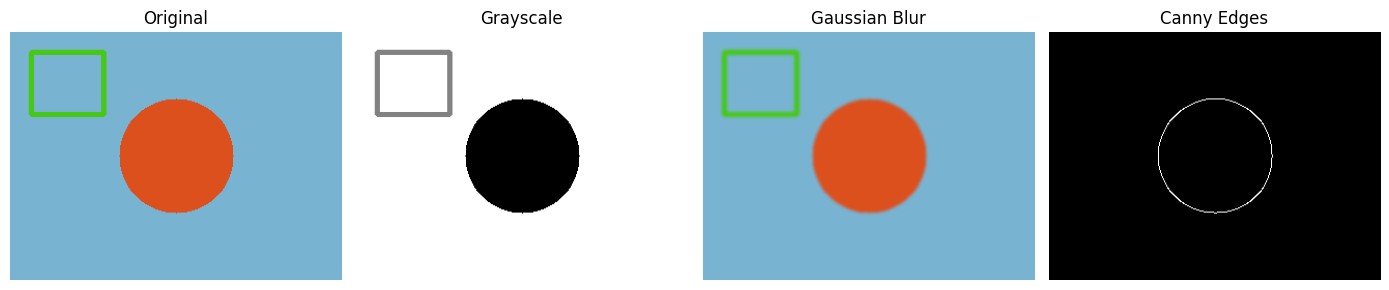

In [1]:
# 1. Perform basic Image Handling and Processing operations on the image.

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Create a sample image so the cell runs without uploading a file
image = np.zeros((240, 320, 3), dtype=np.uint8)
image[:] = (210, 180, 120)
cv2.circle(image, (160, 120), 55, (30, 80, 220), -1)
cv2.rectangle(image, (20, 20), (90, 80), (20, 200, 70), 3)

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
resized = cv2.resize(image, (160, 120))
blurred = cv2.GaussianBlur(image, (7, 7), 0)
edges = cv2.Canny(gray, 80, 160)

print("Original shape:", image.shape)
print("Grayscale shape:", gray.shape)
print("Resized shape:", resized.shape)
print("Image data type:", image.dtype)

fig, ax = plt.subplots(1, 4, figsize=(14, 4))
for a, im, title in zip(ax, [cv2.cvtColor(image, cv2.COLOR_BGR2RGB), gray, cv2.cvtColor(blurred, cv2.COLOR_BGR2RGB), edges],
                        ["Original", "Grayscale", "Gaussian Blur", "Canny Edges"]):
    a.imshow(im, cmap="gray" if len(im.shape) == 2 else None)
    a.set_title(title)
    a.axis("off")
plt.tight_layout()
plt.show()


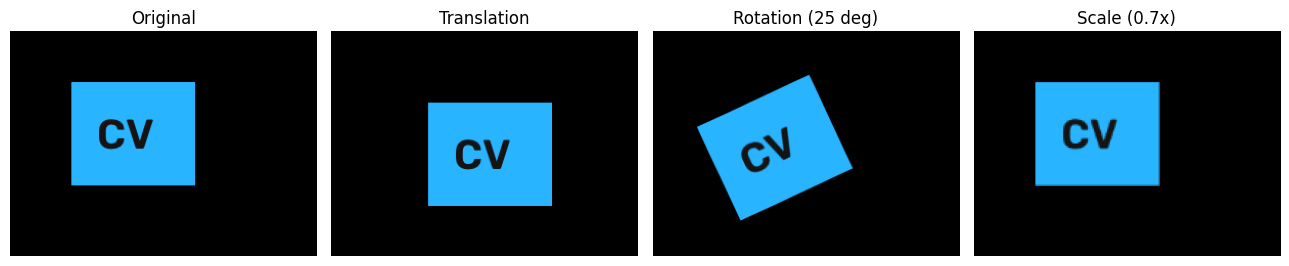

Translation matrix:
 [[ 1.  0. 35.]
 [ 0.  1. 20.]]
Rotation matrix shape: (2, 3)
Scaled image shape: (154, 210, 3)


In [2]:
# 2. Geometric Transformation

import cv2
import numpy as np
import matplotlib.pyplot as plt

image = np.zeros((220, 300, 3), dtype=np.uint8)
cv2.rectangle(image, (60, 50), (180, 150), (255, 180, 40), -1)
cv2.putText(image, "CV", (85, 115), cv2.FONT_HERSHEY_SIMPLEX, 1.4, (20, 20, 20), 3)

rows, cols = image.shape[:2]
translation_matrix = np.float32([[1, 0, 35], [0, 1, 20]])
translated = cv2.warpAffine(image, translation_matrix, (cols, rows))

rotation_matrix = cv2.getRotationMatrix2D((cols / 2, rows / 2), 25, 1.0)
rotated = cv2.warpAffine(image, rotation_matrix, (cols, rows))

scaled = cv2.resize(image, None, fx=0.7, fy=0.7, interpolation=cv2.INTER_LINEAR)

fig, ax = plt.subplots(1, 4, figsize=(13, 3.5))
for a, im, title in zip(ax, [image, translated, rotated, scaled],
                        ["Original", "Translation", "Rotation (25 deg)", "Scale (0.7x)"]):
    a.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    a.set_title(title)
    a.axis("off")
plt.tight_layout()
plt.show()
print("Translation matrix:\n", translation_matrix)
print("Rotation matrix shape:", rotation_matrix.shape)
print("Scaled image shape:", scaled.shape)


In [3]:
# 3. Compute Homography Matrix

import cv2
import numpy as np

# Four corresponding points in two image planes
src = np.float32([[0, 0], [200, 0], [200, 150], [0, 150]])
dst = np.float32([[20, 15], [220, 5], [210, 170], [10, 160]])

H, mask = cv2.findHomography(src, dst, method=0)

print("Homography matrix:")
print(np.round(H, 4))

# Transform the source points and compare with destination points
src_h = np.concatenate([src, np.ones((len(src), 1))], axis=1)
projected_h = (H @ src_h.T).T
projected = projected_h[:, :2] / projected_h[:, 2:3]

print("\nProjected points:")
print(np.round(projected, 2))
print("\nMaximum point error:", round(float(np.max(np.linalg.norm(projected - dst, axis=1))), 4))


Homography matrix:
[[ 8.671e-01 -6.710e-02  2.000e+01]
 [-5.300e-02  9.602e-01  1.500e+01]
 [-6.000e-04 -0.000e+00  1.000e+00]]

Projected points:
[[ 20.  15.]
 [220.   5.]
 [210. 170.]
 [ 10. 160.]]

Maximum point error: 0.0


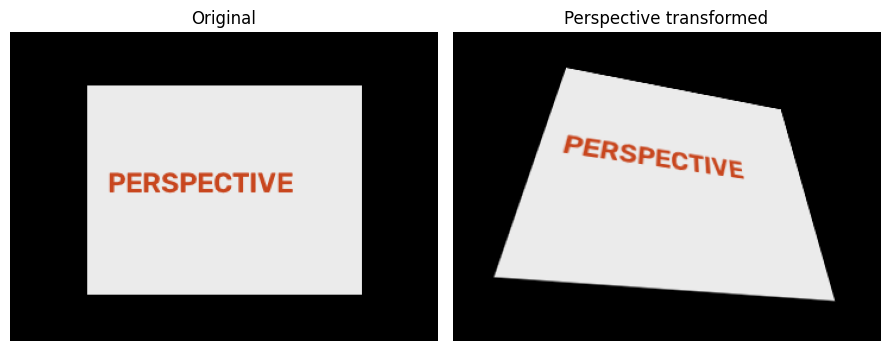

Perspective matrix shape: (3, 3)
Warped image shape: (260, 360, 3)


In [4]:
# 4. Perspective Transformation

import cv2
import numpy as np
import matplotlib.pyplot as plt

image = np.zeros((260, 360, 3), dtype=np.uint8)
cv2.rectangle(image, (65, 45), (295, 220), (235, 235, 235), -1)
cv2.putText(image, "PERSPECTIVE", (82, 135), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (30, 70, 200), 2)

src = np.float32([[65, 45], [295, 45], [295, 220], [65, 220]])
dst = np.float32([[95, 30], [275, 65], [320, 225], [35, 205]])
M = cv2.getPerspectiveTransform(src, dst)
warped = cv2.warpPerspective(image, M, (image.shape[1], image.shape[0]))

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB)); ax[0].set_title("Original")
ax[1].imshow(cv2.cvtColor(warped, cv2.COLOR_BGR2RGB)); ax[1].set_title("Perspective transformed")
for a in ax: a.axis("off")
plt.tight_layout()
plt.show()

print("Perspective matrix shape:", M.shape)
print("Warped image shape:", warped.shape)


In [5]:
# 5. Camera Calibration

import cv2
import numpy as np

# Demonstration with synthetic chessboard-corner observations.
# Real calibration should use corners detected in multiple chessboard photos.
pattern_size = (7, 6)
square_size = 1.0

objp = np.zeros((pattern_size[0] * pattern_size[1], 3), np.float32)
objp[:, :2] = np.mgrid[0:pattern_size[0], 0:pattern_size[1]].T.reshape(-1, 2)
objp *= square_size

image_size = (640, 480)
objpoints = []
imgpoints = []

# Create several plausible 2D corner sets from the planar grid
for i in range(8):
    pts = objp[:, :2].copy()
    pts[:, 0] = 500 + (pts[:, 0] - 3) * (35 + i)
    pts[:, 1] = 350 + (pts[:, 1] - 2.5) * (34 + i * 0.7)
    pts += np.random.default_rng(i).normal(0, 0.15, pts.shape).astype(np.float32)
    imgpoints.append(pts.reshape(-1, 1, 2))
    objpoints.append(objp.copy())

# Synthetic observations are for demonstrating the API, not precision calibration.
rms, camera_matrix, dist_coeffs, rvecs, tvecs = cv2.calibrateCamera(
    objpoints, imgpoints, image_size, None, None
)

print("Calibration RMS error:", round(rms, 4))
print("Camera matrix shape:", camera_matrix.shape)
print("Distortion coefficients shape:", dist_coeffs.shape)
print("Number of calibration views:", len(objpoints))
print("\nCamera matrix:\n", np.round(camera_matrix, 3))


Calibration RMS error: 0.1954
Camera matrix shape: (3, 3)
Distortion coefficients shape: (1, 5)
Number of calibration views: 8

Camera matrix:
 [[8.3929780e+04 0.0000000e+00 4.0224000e+02]
 [0.0000000e+00 7.6519757e+04 1.0220000e+02]
 [0.0000000e+00 0.0000000e+00 1.0000000e+00]]


In [6]:
# 6. Compute Fundamental Matrix

import cv2
import numpy as np

rng = np.random.default_rng(7)
n = 30

# Generate matching points with a simple stereo-like horizontal displacement.
pts1 = rng.uniform(50, 400, (n, 2)).astype(np.float32)
disparity = rng.uniform(5, 30, (n, 1)).astype(np.float32)
pts2 = pts1.copy()
pts2[:, 0:1] -= disparity
pts1_cv = pts1.reshape(-1, 1, 2)
pts2_cv = pts2.reshape(-1, 1, 2)

F, inliers = cv2.findFundamentalMat(pts1_cv, pts2_cv, cv2.FM_RANSAC, 1.0, 0.99)

print("Fundamental matrix:")
print(F)
print("Matrix shape:", None if F is None else F.shape)
print("Number of inliers:", 0 if inliers is None else int(inliers.sum()))
print("Number of correspondences:", n)

# Epipolar constraint: x2^T F x1 should be near zero for inlier matches.
if F is not None and F.shape == (3, 3):
    x1 = np.hstack([pts1, np.ones((n, 1))])
    x2 = np.hstack([pts2, np.ones((n, 1))])
    errors = np.abs(np.sum(x2 * (F @ x1.T).T, axis=1))
    print("Mean epipolar constraint error:", float(np.mean(errors)))


Fundamental matrix:
[[ 1.23902091e-06 -1.21148711e-05  3.58027808e-03]
 [ 2.20270384e-05  4.40540767e-06  1.93859225e+12]
 [-6.62023734e-03 -1.93859225e+12  1.00000000e+00]]
Matrix shape: (3, 3)
Number of inliers: 30
Number of correspondences: 30
Mean epipolar constraint error: 0.08020833333333334


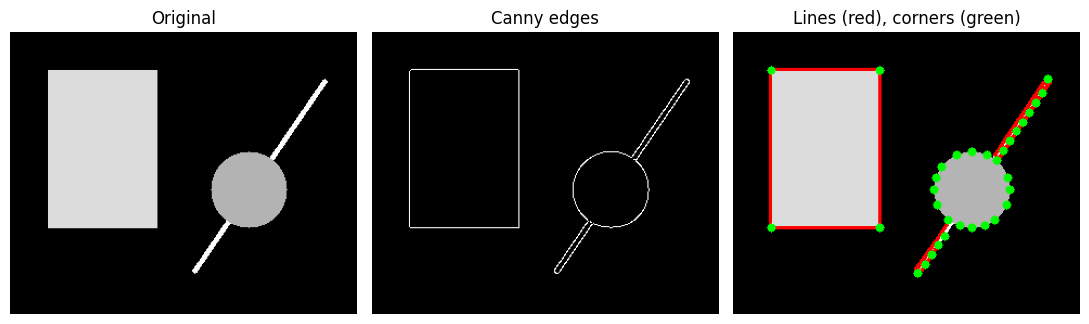

Detected line segments: 12
Detected corners: 33


In [9]:
# 7. Edge Detection, Line Detection and Corner Detection

import cv2
import matplotlib.pyplot as plt
import numpy as np

# 1. Create a blank grayscale image and draw shapes
image = np.zeros((260, 320), dtype=np.uint8)
cv2.rectangle(image, (35, 35), (135, 180), 220, -1)
cv2.line(image, (170, 220), (290, 45), 255, 4)
cv2.circle(image, (220, 145), 35, 180, -1)

# 2. Edge detection & Hough Line Transform
edges = cv2.Canny(image, 60, 150)
lines = cv2.HoughLinesP(
    edges, 1, np.pi / 180, threshold=25, minLineLength=25, maxLineGap=8
)

color = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)
line_count = 0

if lines is not None:
  line_count = len(lines)
  for line in lines:
    x1, y1, x2, y2 = line.ravel()  # Safely unpacks (1, 4) or (4,) shapes
    cv2.line(color, (int(x1), int(y1)), (int(x2), int(y2)), (0, 0, 255), 2)

# 3. Shi-Tomasi Corner Detection
corners = cv2.goodFeaturesToTrack(
    image, maxCorners=50, qualityLevel=0.01, minDistance=10
)
corner_count = 0 if corners is None else len(corners)

if corners is not None:
  for c in np.intp(corners):
    x, y = c.ravel()
    cv2.circle(color, (int(x), int(y)), 4, (0, 255, 0), -1)

# 4. Visualization
fig, ax = plt.subplots(1, 3, figsize=(11, 3.5))
ax[0].imshow(image, cmap="gray")
ax[0].set_title("Original")

ax[1].imshow(edges, cmap="gray")
ax[1].set_title("Canny edges")

ax[2].imshow(cv2.cvtColor(color, cv2.COLOR_BGR2RGB))
ax[2].set_title("Lines (red), corners (green)")

for a in ax:
  a.axis("off")

plt.tight_layout()
plt.show()

print("Detected line segments:", line_count)
print("Detected corners:", corner_count)


Number of keypoints: 62
Descriptor shape: (62, 128)
Descriptor data type: float32


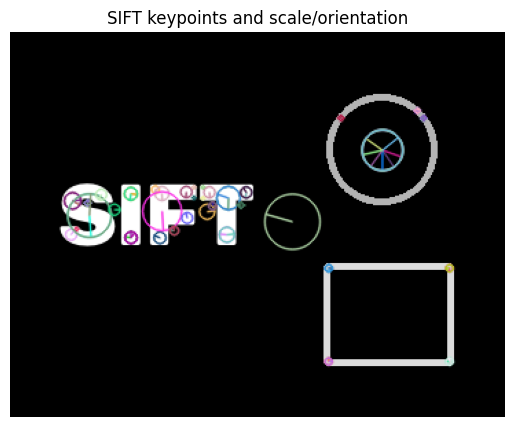

In [10]:
# 8. SIFT Feature Descriptor

import cv2
import numpy as np
import matplotlib.pyplot as plt

image = np.zeros((280, 360), dtype=np.uint8)
cv2.putText(image, "SIFT", (35, 155), cv2.FONT_HERSHEY_COMPLEX, 2.2, 255, 4)
cv2.circle(image, (270, 85), 38, 180, 3)
cv2.rectangle(image, (230, 170), (320, 240), 220, 3)

sift = cv2.SIFT_create(nfeatures=250)
keypoints, descriptors = sift.detectAndCompute(image, None)
visual = cv2.drawKeypoints(image, keypoints, None,
                           flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

print("Number of keypoints:", len(keypoints))
print("Descriptor shape:", None if descriptors is None else descriptors.shape)
print("Descriptor data type:", None if descriptors is None else descriptors.dtype)

plt.figure(figsize=(8, 5))
plt.imshow(visual, cmap="gray")
plt.title("SIFT keypoints and scale/orientation")
plt.axis("off")
plt.show()


In [1]:
# 9. SURF and HOG Feature Descriptor

import cv2
import numpy as np
import matplotlib.pyplot as plt

print(cv2.__file__)
print(hasattr(cv2, "HOGDescriptor"))


image = np.zeros((128, 64), dtype=np.uint8)
cv2.rectangle(image, (12, 15), (50, 112), 220, -1)
cv2.line(image, (12, 15), (50, 112), 255, 3)

# HOG descriptor
hog = cv2.HOGDescriptor(
    _winSize=(64, 128),
    _blockSize=(16, 16),
    _blockStride=(8, 8),
    _cellSize=(8, 8),
    _nbins=9
)
hog_features = hog.compute(image)

print("HOG descriptor length:", len(hog_features))
print("HOG descriptor shape:", hog_features.shape)

# SURF is often unavailable in standard Colab OpenCV builds because it
# belongs to the non-free/contrib feature set. Check availability safely.
if hasattr(cv2, "xfeatures2d") and hasattr(cv2.xfeatures2d, "SURF_create"):
    try:
        surf = cv2.xfeatures2d.SURF_create()
        keypoints, surf_descriptors = surf.detectAndCompute(image, None)
        print("SURF keypoints:", len(keypoints))
        print("SURF descriptor shape:",
              None if surf_descriptors is None else surf_descriptors.shape)
    except cv2.error:
        print("SURF is present but disabled in this OpenCV build.")
else:
    print("SURF is unavailable in this OpenCV build; HOG ran successfully.")

plt.figure(figsize=(3, 5))
plt.imshow(image, cmap="gray")
plt.title("Image used for HOG / SURF")
plt.axis("off")
plt.show()



/usr/local/lib/python3.13/dist-packages/cv2/__init__.py
False


AttributeError: module 'cv2' has no attribute 'HOGDescriptor'

In [4]:
!pip install --force-reinstall --no-cache-dir opencv-python-headless


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.2/61.2 MB 101.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.7/15.7 MB 177.1 MB/s  0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.4.6
    Uninstalling numpy-2.4.6:
      Successfully uninstalled numpy-2.4.6
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 5.0.0.93
    Uninstalling opencv-python-headless-5.0.0.93:
      Successfully uninstalled opencv-python-headless-5.0.0.93
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [opencv-python-headless]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires opencv-python>=3.4.8.29, which is not installed.
numba 0.64.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.5 which is incompatible.
